# D3 · Exploratory Data Analysis: Predicting Engine Life
**ANCP Group P** · Module M3 · TCS (analytics partner) for GE Aerospace (client) · Sprint 3 (Agile) · Data version `data-v1.0`

**Business question (from the D1 charter).** *When should each in-service engine be taken off the aircraft for repair?* Analytics layers: **predictive** (RUL forecast, RMSE >= 15% below baseline), **prescriptive** (repair-timing rule) and **simulation** (cost vs a fixed-interval schedule).

**How to run.** Kernel > Restart & Run All. The notebook reads the cleaned CSV files from D2 (`FD00x_train_clean.csv`, `FD00x_test_clean.csv`); if only the Excel versions are present it falls back to them. On Databricks add your Volume path to `DATA_DIRS`. Every random operation uses `SEED = 42`.

**Sprint 3 stories covered here:** S3-1 distributions and lifetimes · S3-2 sensor trends and relationships · S3-3 segments · S3-4 representativeness repeated on cleaned data · S3-5 insight log and modelling implications.

## 1. Hypotheses (stated BEFORE looking at any result)
Each hypothesis has a pre-set pass criterion and a link to the business question. The scorecard in Section 8 applies these criteria mechanically.

| ID | Hypothesis | Pass criterion (fixed in advance) | Link to business question |
|---|---|---|---|
| H1 | Engine lives vary so much that any single fixed removal interval wastes a lot of life | Coefficient of variation of life >= 0.20 **and** a no-failure fixed interval (= shortest observed life) leaves >= 35% of average life unused | Value of a RUL-based rule over a fixed-interval schedule (simulation) |
| H2 | Several sensors drift steadily toward failure, so RUL is predictable from sensors | >= 5 sensors with abs Spearman correlation >= 0.5 against capped RUL | Predictive: RMSE target is feasible |
| H3 | In FD004, operating regime hides the degradation signal; regime-wise normalisation reveals it | Median share of raw-sensor variance explained by regime >= 0.50 **and** normalisation raises abs correlation with RUL for >= 50% of sensors | Predictive: why D2 normalised per regime; FD004 is the harder case |
| H4 | Degradation is visible only late in life (roughly the last 125 cycles) | Signal change over the early stretch (RUL 120 to 240) <= 25% of the change over the last 120 cycles | Prescriptive: when to start acting; supports RUL cap of 125 |
| H5 | Total life cannot be predicted from an engine's early readings | Max abs Spearman between first-20-cycle sensor means and total life < 0.30 | Prescriptive: removal must be decided in service, not at delivery |
| H6 | Short-lived engines degrade faster near the end (life is driven by degradation rate) | Spearman(late-life slope, total life) <= -0.30 | Predictive/prescriptive: engine-specific trend features are needed |
| H7 | The test engines are representative of the training engines (no train/test shift) | >= 90% of sensors have KS distance < 0.10 over the first 30 cycles **and** lifetime KS p > 0.05 | Validity of every accuracy and cost claim |
| H8 | FD004 is harder than FD001 | FD004 has higher life CV **and** lower median abs correlation of its top-5 sensors | Charter risk 4; report FD004 separately |

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.25,'axes.spines.top':False,
                     'axes.spines.right':False,'font.size':9,'axes.titlesize':10,'axes.titleweight':'bold'})
SEED = 42; np.random.seed(SEED)
DATA_DIRS = ['data-v1.0','data','../data','../data-v1.0','/mnt/user-data/outputs/repo/data-v1.0']  # add your Databricks Volume path here
OUT = 'eda_outputs'; os.makedirs(OUT, exist_ok=True)
FDS = ['FD001','FD004']; COL = {'FD001':'#1f77b4','FD004':'#e8731a'}

def load(fd, split):
    for d in DATA_DIRS:
        p = f'{d}/{fd}_{split}_clean.csv'
        if os.path.exists(p): return pd.read_csv(p)
    for d in DATA_DIRS:   # fallback: Excel files stored in the GitHub repo
        for name in (f'{d}/{fd}_{split}_clean_data-v1.0.xlsx', f'{d}/ANCP_GroupP_D2_cleaned_{fd}_data-v1.0.xlsx'):
            if os.path.exists(name): return pd.read_excel(name, sheet_name=f'{fd}_{split}')
    raise FileNotFoundError(f'{fd}_{split} not found in {DATA_DIRS}')

D  = {fd:{sp:load(fd,sp) for sp in ['train','test']} for fd in FDS}
ZC = {fd:[c for c in D[fd]['train'].columns if c.endswith('_z')] for fd in FDS}
R  = {}   # results store, reused by the scorecard and the PDF
def save(name): plt.savefig(f'{OUT}/{name}.png', dpi=160, bbox_inches='tight'); plt.show()
pd.DataFrame([{'subset':fd,'split':sp,'rows':len(d),'engines':d.unit.nunique(),'columns':d.shape[1],
               'missing':int(d.isna().sum().sum())} for fd in FDS for sp,d in D[fd].items()])

,subset,split,rows,engines,columns,missing
0,FD001,train,20631,100,38,0
1,FD001,test,13096,100,38,0
2,FD004,train,61249,249,51,0
3,FD004,test,41214,248,51,0


## 2. Distributions: engine lifetimes (H1)
A fixed-interval schedule must pick one removal age for every engine. The chart on the right shows the trade-off it faces.

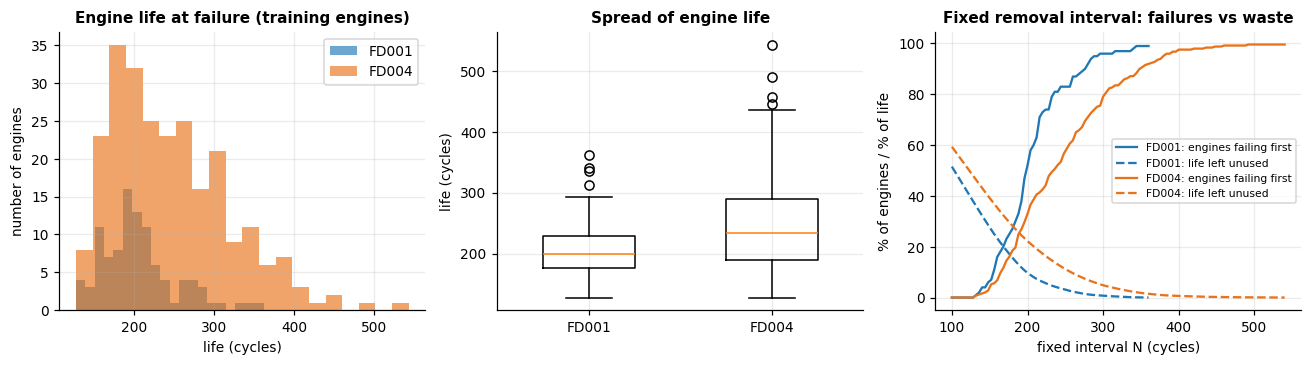

,FD001,FD004
mean,206.310,245.980
sd,46.343,73.111
cv,0.225,0.297
min,128.000,128.000
median,199.000,234.000
max,362.000,543.000
unused_at_min,0.380,0.480
p5,147.000,151.400
fail_at_p5,0.040,0.052
unused_at_p5,0.290,0.386


In [2]:
life = {fd:D[fd]['train'].groupby('unit').cycle.max() for fd in FDS}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for fd in FDS: ax[0].hist(life[fd], bins=20, alpha=.65, label=fd, color=COL[fd])
ax[0].set(title='Engine life at failure (training engines)', xlabel='life (cycles)', ylabel='number of engines'); ax[0].legend()
ax[1].boxplot([life[f] for f in FDS], labels=FDS, widths=.5); ax[1].set(title='Spread of engine life', ylabel='life (cycles)')
for fd in FDS:
    L = life[fd].values; N = np.arange(100, int(L.max()), 4)
    ax[2].plot(N, [(L < n).mean()*100 for n in N], color=COL[fd], label=f'{fd}: engines failing first')
    ax[2].plot(N, [np.clip(L-n, 0, None).sum()/L.sum()*100 for n in N], color=COL[fd], ls='--', label=f'{fd}: life left unused')
ax[2].set(title='Fixed removal interval: failures vs waste', xlabel='fixed interval N (cycles)', ylabel='% of engines / % of life'); ax[2].legend(fontsize=7)
plt.tight_layout(); save('f1_lifetimes')
for fd in FDS:
    L = life[fd].values; p5 = np.percentile(L, 5)
    R[f'H1_{fd}'] = dict(mean=L.mean(), sd=L.std(ddof=1), cv=L.std(ddof=1)/L.mean(), min=int(L.min()), median=float(np.median(L)), max=int(L.max()),
        unused_at_min=(L.mean()-L.min())/L.mean(), p5=p5, fail_at_p5=(L < p5).mean(), unused_at_p5=np.clip(L-p5, 0, None).sum()/L.sum())
pd.DataFrame({fd:R[f'H1_{fd}'] for fd in FDS}).round(3)

## 3. Relationships: which sensors track degradation? (H2, H4)
Spearman correlation (rank-based, robust to non-linear drift) between each regime-normalised sensor (`_z`) and capped RUL, training engines only.

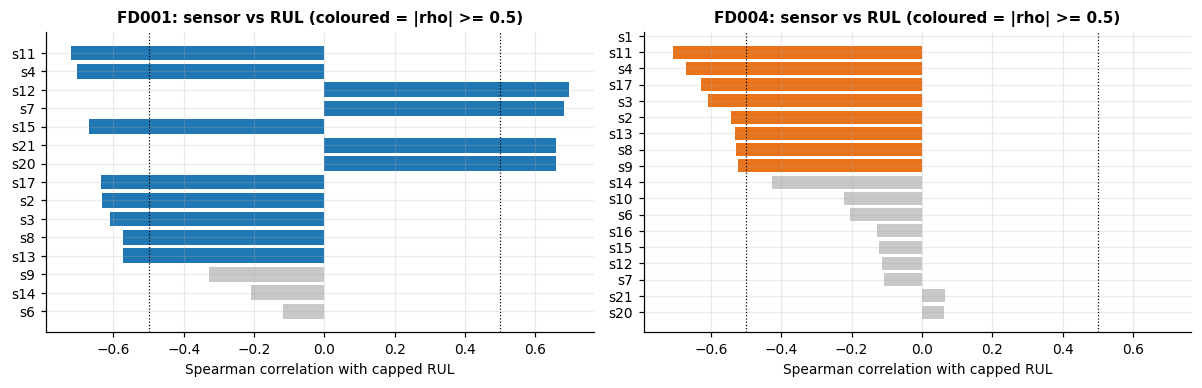

,FD001,FD004
n_strong,12,8
top,"[s11, s4, s12]","[s11, s4, s17]"
top_rho,"[-0.72, -0.705, 0.695]","[-0.708, -0.672, -0.627]"
top5_median_abs,0.695352,0.627372


In [3]:
corr = {fd:D[fd]['train'][ZC[fd]].corrwith(D[fd]['train'].RUL_cap, method='spearman') for fd in FDS}
TOP  = {fd:list(corr[fd].abs().sort_values(ascending=False).index[:3]) for fd in FDS}
SIGN = {fd:np.sign(corr[fd][TOP[fd]]).values for fd in FDS}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for a, fd in zip(ax, FDS):
    s = corr[fd].reindex(corr[fd].abs().sort_values().index)
    a.barh([i.replace('_z','') for i in s.index], s.values, color=[COL[fd] if abs(v) >= .5 else '#c8c8c8' for v in s.values])
    a.axvline(.5, ls=':', c='k', lw=.8); a.axvline(-.5, ls=':', c='k', lw=.8)
    a.set(title=f'{fd}: sensor vs RUL (coloured = |rho| >= 0.5)', xlabel='Spearman correlation with capped RUL')
plt.tight_layout(); save('f2_sensor_corr')
for fd in FDS:
    R[f'H2_{fd}'] = dict(n_strong=int((corr[fd].abs() >= .5).sum()), top=[t.replace('_z','') for t in TOP[fd]], top_rho=[round(float(corr[fd][t]), 3) for t in TOP[fd]],
                         top5_median_abs=float(corr[fd].abs().sort_values(ascending=False).iloc[:5].median()))
pd.DataFrame({fd:R[f'H2_{fd}'] for fd in FDS})

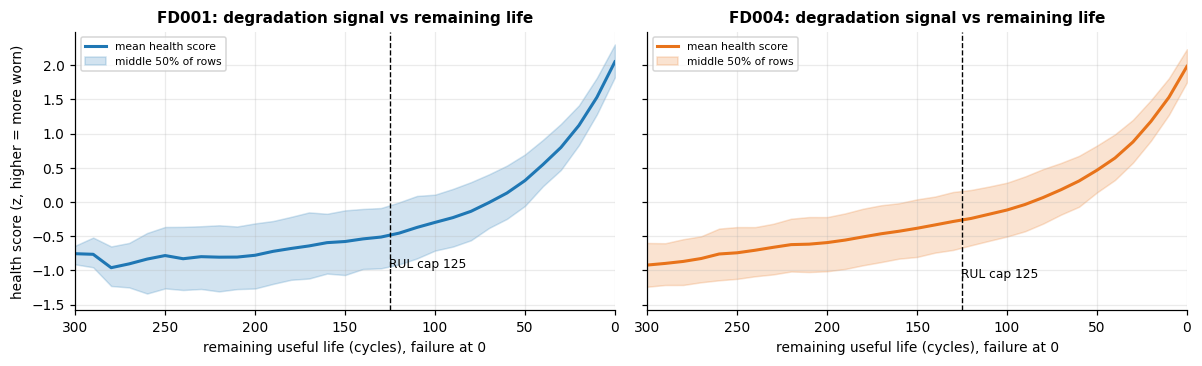

,FD001,FD004
change_last120,2.507,2.224
change_early,0.374,0.465
ratio,0.149,0.209


In [4]:
def score(df, fd):   # one health score: mean of the 3 strongest sensors, sign-flipped so that HIGHER = MORE DEGRADED
    return (df[TOP[fd]].values * np.where(SIGN[fd] < 0, 1, -1)).mean(axis=1)
for fd in FDS:
    for sp in ['train','test']: D[fd][sp]['score'] = score(D[fd][sp], fd)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, fd in zip(ax, FDS):
    d = D[fd]['train']; b = (d.RUL//10*10); m = d.groupby(b).score.mean(); q1 = d.groupby(b).score.quantile(.25); q3 = d.groupby(b).score.quantile(.75)
    a.plot(m.index, m.values, color=COL[fd], lw=2, label='mean health score'); a.fill_between(m.index, q1.values, q3.values, color=COL[fd], alpha=.2, label='middle 50% of rows')
    a.axvline(125, ls='--', c='k', lw=.9); a.text(128, a.get_ylim()[1]*.85 if False else m.min(), ' RUL cap 125', fontsize=8)
    a.set(title=f'{fd}: degradation signal vs remaining life', xlabel='remaining useful life (cycles), failure at 0', xlim=(300, 0)); a.legend(fontsize=7)
ax[0].set_ylabel('health score (z, higher = more worn)')
plt.tight_layout(); save('f3_trajectory')
for fd in FDS:
    d = D[fd]['train']; m = d.groupby(d.RUL//10*10).score.mean()
    g_low, g_high = m[0]-m[120], m[120]-m[240]
    R[f'H4_{fd}'] = dict(change_last120=float(g_low), change_early=float(g_high), ratio=float(abs(g_high)/abs(g_low)))
pd.DataFrame({fd:R[f'H4_{fd}'] for fd in FDS}).round(3)

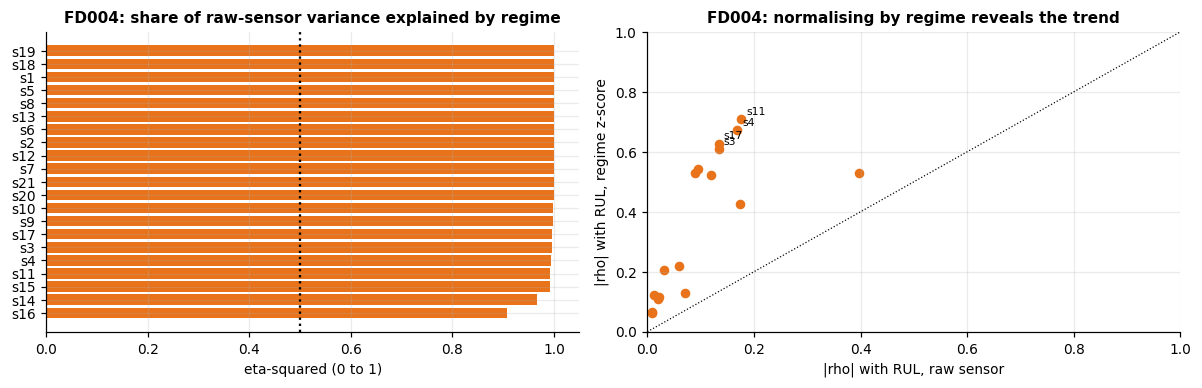

median_eta2        1.000
share_improved     1.000
n                 21.000
best_raw           0.398
best_z             0.708
dtype: float64

In [5]:
# FD004 only (H3): how much of each raw sensor's variance is just the operating regime?
d = D['FD004']['train']; raw = [c[:-2] for c in ZC['FD004']]
eta = {}
for c in raw:
    g = d.groupby('condition_id')[c]; eta[c] = float((g.count()*(g.mean()-d[c].mean())**2).sum() / ((d[c]-d[c].mean())**2).sum())
rho_raw = {c:abs(stats.spearmanr(d[c], d.RUL_cap)[0]) for c in raw}; rho_z = {c:abs(stats.spearmanr(d[c+'_z'], d.RUL_cap)[0]) for c in raw}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
e = pd.Series(eta).sort_values(); ax[0].barh(e.index, e.values, color=COL['FD004']); ax[0].axvline(.5, ls=':', c='k')
ax[0].set(title='FD004: share of raw-sensor variance explained by regime', xlabel='eta-squared (0 to 1)')
x = np.array([rho_raw[c] for c in raw]); y = np.array([rho_z[c] for c in raw])
ax[1].scatter(x, y, color=COL['FD004'], s=28); ax[1].plot([0, 1], [0, 1], 'k:', lw=.8)
for c, xi, yi in zip(raw, x, y):
    if yi > .55: ax[1].annotate(c, (xi, yi), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[1].set(title='FD004: normalising by regime reveals the trend', xlabel='|rho| with RUL, raw sensor', ylabel='|rho| with RUL, regime z-score', xlim=(0, 1), ylim=(0, 1))
plt.tight_layout(); save('f4_regime_effect')
R['H3'] = dict(median_eta2=float(np.median(list(eta.values()))), share_improved=float(np.nanmean((y > x)[~np.isnan(y)])), n=len(raw),
               best_raw=float(np.nanmax(x)), best_z=float(np.nanmax(y)))
pd.Series(R['H3']).round(3)

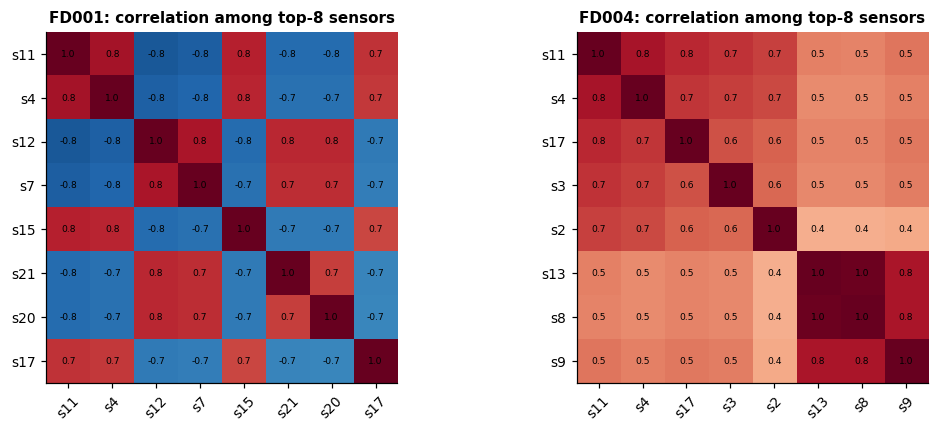

pairs with |r| > 0.9 among top-8: {'FD001': 0, 'FD004': 1}


In [6]:
# redundancy between the strongest sensors (modelling implication: multicollinearity)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, fd in zip(ax, FDS):
    top8 = list(corr[fd].abs().sort_values(ascending=False).index[:8]); M = D[fd]['train'][top8].corr().values
    im = a.imshow(M, cmap='RdBu_r', vmin=-1, vmax=1); a.set_xticks(range(8)); a.set_yticks(range(8))
    a.set_xticklabels([t.replace('_z','') for t in top8], rotation=45); a.set_yticklabels([t.replace('_z','') for t in top8])
    for i in range(8):
        for j in range(8): a.text(j, i, f'{M[i,j]:.1f}', ha='center', va='center', fontsize=6)
    a.set_title(f'{fd}: correlation among top-8 sensors'); a.grid(False)
    R[f'red_{fd}'] = int(((np.abs(M) > .9).sum() - 8)//2)
plt.tight_layout(); save('f5_redundancy'); print('pairs with |r| > 0.9 among top-8:', {fd:R[f'red_{fd}'] for fd in FDS})

## 4. Segments (H5, H6, regimes)
Segments: engines by lifetime (short / medium / long) and rows by FD004 operating regime.

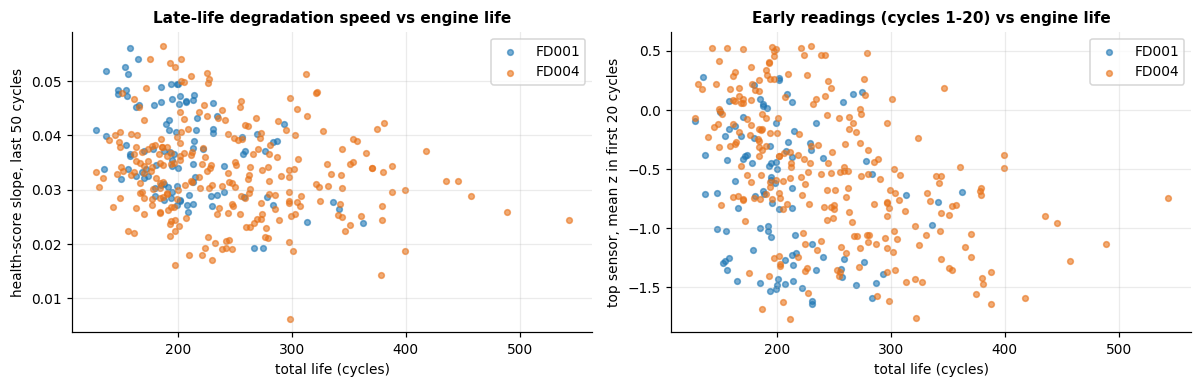

,FD001,FD004
H5 max |rho| early vs life,0.277,0.544
H6 rho slope vs life,-0.356,-0.146


In [7]:
def engine_table(fd):
    d = D[fd]['train']; top = [t for t in TOP[fd]]
    t = pd.DataFrame({'life':d.groupby('unit').cycle.max()})
    for c in top: t[f'early_{c}'] = d[d.cycle <= 20].groupby('unit')[c].mean()
    t['slope'] = d[d.RUL <= 50].groupby('unit').apply(lambda g: np.polyfit(g.cycle, g.score, 1)[0])
    t['segment'] = pd.qcut(t.life, 3, labels=['short-lived','medium','long-lived'])
    return t
ET = {fd:engine_table(fd) for fd in FDS}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for fd in FDS:
    ax[0].scatter(ET[fd].life, ET[fd].slope, s=14, alpha=.6, color=COL[fd], label=fd)
ax[0].set(title='Late-life degradation speed vs engine life', xlabel='total life (cycles)', ylabel='health-score slope, last 50 cycles'); ax[0].legend()
ax[1].scatter(ET['FD001'].life, ET['FD001'][f'early_{TOP["FD001"][0]}'], s=14, alpha=.6, color=COL['FD001'], label='FD001')
ax[1].scatter(ET['FD004'].life, ET['FD004'][f'early_{TOP["FD004"][0]}'], s=14, alpha=.6, color=COL['FD004'], label='FD004')
ax[1].set(title='Early readings (cycles 1-20) vs engine life', xlabel='total life (cycles)', ylabel='top sensor, mean z in first 20 cycles'); ax[1].legend()
plt.tight_layout(); save('f6_segments_engines')
for fd in FDS:
    t = ET[fd]; ec = [c for c in t.columns if c.startswith('early_')]
    r5 = {c:float(stats.spearmanr(t[c], t.life)[0]) for c in ec}
    R[f'H5_{fd}'] = dict(max_abs_rho=max(abs(v) for v in r5.values()), rhos=r5)
    R[f'H6_{fd}'] = dict(rho=float(stats.spearmanr(t.slope, t.life)[0]), slope_by_segment=t.groupby('segment').slope.mean().round(4).to_dict())
pd.DataFrame({fd:{'H5 max |rho| early vs life':R[f'H5_{fd}']['max_abs_rho'], 'H6 rho slope vs life':R[f'H6_{fd}']['rho']} for fd in FDS}).round(3)

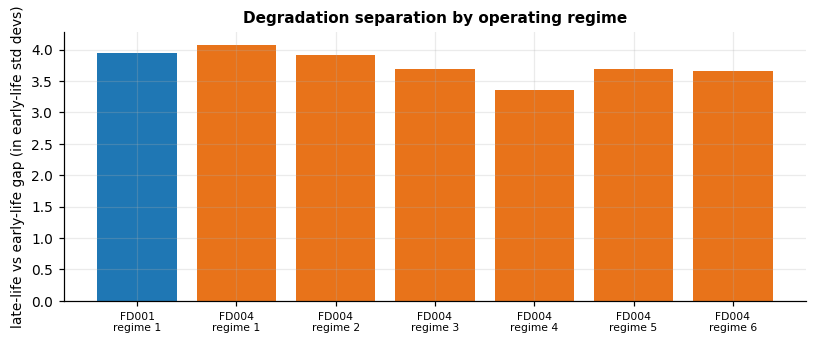

,subset,regime,rows,share,effect
0,FD001,1,20631,1.000,3.945
1,FD004,1,9238,0.151,4.078
2,FD004,2,9224,0.151,3.909
3,FD004,3,9091,0.148,3.695
4,FD004,4,9139,0.149,3.350
5,FD004,5,9162,0.150,3.689
6,FD004,6,15395,0.251,3.654


In [8]:
# regime segments (FD004 has 6; FD001 has 1): does the degradation signal separate late-life from early-life in EVERY regime?
rows = []
for fd in FDS:
    d = D[fd]['train']
    for k, g in d.groupby('condition_id'):
        early, late = g[g.RUL >= 150].score, g[g.RUL <= 30].score
        rows.append(dict(subset=fd, regime=k, rows=len(g), share=len(g)/len(d), effect=(late.mean()-early.mean())/early.std()))
SEG = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
lab = [f"{r.subset}\nregime {r.regime}" for r in SEG.itertuples()]
ax.bar(lab, SEG.effect, color=[COL[s] for s in SEG.subset]); ax.set(title='Degradation separation by operating regime', ylabel='late-life vs early-life gap (in early-life std devs)')
ax.axhline(0, c='k', lw=.6); plt.xticks(fontsize=7); plt.tight_layout(); save('f7_regime_segments')
R['regime_effect'] = dict(min=float(SEG.effect.min()), max=float(SEG.effect.max()), fd004_min=float(SEG[SEG.subset=='FD004'].effect.min()), fd004_max=float(SEG[SEG.subset=='FD004'].effect.max()))
SEG.round(3)

## 5. Representativeness and bias checks, repeated on the cleaned data (H7)
Same checks as D2 Section 4, now on `data-v1.0`. Early-life rows (cycles 1 to 30) are compared because test engines stop before failure, so later rows are legitimately different.

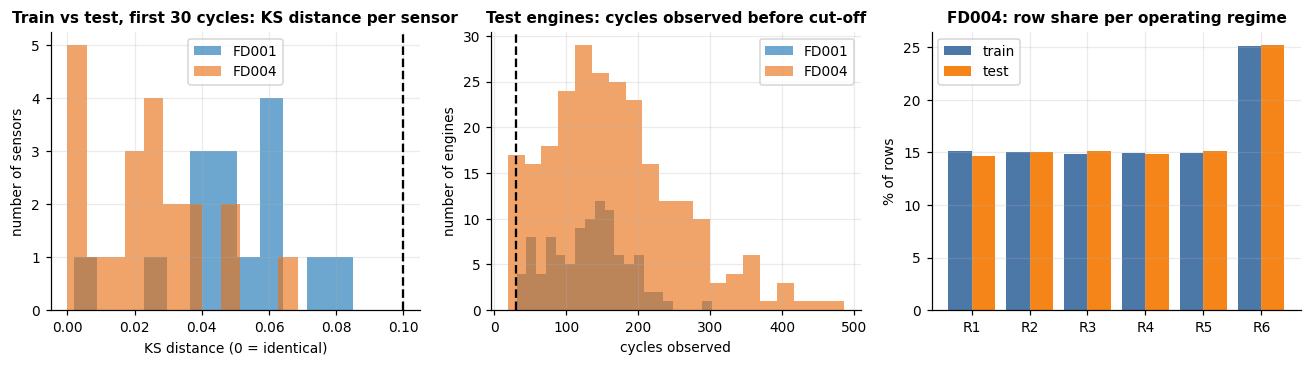

,FD001,FD004
share_ks_below_010,1.000,1.000
max_ks,0.085,0.069
life_ks_p,0.994,0.858
test_short_hist,0.000,11.000
test_min_obs,31.000,19.000
test_median_obs,133.500,153.500
outlier_rate_train,0.012,0.019
outlier_rate_test,0.000,0.012
capped_share,0.389,0.488


In [9]:
ks = {}
for fd in FDS:
    tr, te = D[fd]['train'], D[fd]['test']
    ks[fd] = pd.Series({c.replace('_z',''):stats.ks_2samp(tr[tr.cycle <= 30][c], te[te.cycle <= 30][c]).statistic for c in ZC[fd]})
lifetot = {fd:(D[fd]['test'].groupby('unit').cycle.max() + D[fd]['test'].groupby('unit').RUL.min()) for fd in FDS}
obs = {fd:D[fd]['test'].groupby('unit').cycle.max() for fd in FDS}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for fd in FDS: ax[0].hist(ks[fd], bins=12, alpha=.65, color=COL[fd], label=fd)
ax[0].axvline(.10, ls='--', c='k'); ax[0].set(title='Train vs test, first 30 cycles: KS distance per sensor', xlabel='KS distance (0 = identical)', ylabel='number of sensors'); ax[0].legend()
for fd in FDS: ax[1].hist(obs[fd], bins=20, alpha=.65, color=COL[fd], label=fd)
ax[1].axvline(30, ls='--', c='k'); ax[1].set(title='Test engines: cycles observed before cut-off', xlabel='cycles observed', ylabel='number of engines'); ax[1].legend()
sh = pd.concat({fd:pd.DataFrame({'train':D[fd]['train'].condition_id.value_counts(normalize=True).sort_index(), 'test':D[fd]['test'].condition_id.value_counts(normalize=True).sort_index()}) for fd in ['FD004']})
x = np.arange(len(sh)); ax[2].bar(x-.2, sh.train.values*100, .4, label='train', color='#4c78a8'); ax[2].bar(x+.2, sh.test.values*100, .4, label='test', color='#f58518')
ax[2].set_xticks(x); ax[2].set_xticklabels([f'R{i[1]}' for i in sh.index]); ax[2].set(title='FD004: row share per operating regime', ylabel='% of rows'); ax[2].legend()
plt.tight_layout(); save('f8_representativeness')
for fd in FDS:
    tr_life = life[fd]; R[f'H7_{fd}'] = dict(share_ks_below_010=float((ks[fd] < .10).mean()), max_ks=float(ks[fd].max()), life_ks_p=float(stats.ks_2samp(tr_life, lifetot[fd]).pvalue),
        test_short_hist=int((obs[fd] < 30).sum()), test_min_obs=int(obs[fd].min()), test_median_obs=float(obs[fd].median()),
        outlier_rate_train=float(D[fd]['train'].outlier_flag.mean()), outlier_rate_test=float(D[fd]['test'].outlier_flag.mean()),
        capped_share=float((D[fd]['train'].RUL > 125).mean()))
R['regime_share_maxdiff'] = float((sh.train - sh.test).abs().max())
pd.DataFrame({fd:R[f'H7_{fd}'] for fd in FDS}).round(3)

In [10]:
# coverage gaps that no cleaning can fix (bias statement)
print('Single simulated engine class; FD001 has 1 regime/1 fault mode, FD004 has 6 regimes/2 fault modes.')
print('No maintenance events, sensor faults or real-world missingness; sensor noise is synthetic.')
print('Life is right-skewed: engines above', {fd:int(np.percentile(life[fd], 90)) for fd in FDS}, 'cycles (90th pct) are rare, so RUL for long-lived engines will be less certain.')

Single simulated engine class; FD001 has 1 regime/1 fault mode, FD004 has 6 regimes/2 fault modes.
No maintenance events, sensor faults or real-world missingness; sensor noise is synthetic.
Life is right-skewed: engines above {'FD001': 275, 'FD004': 347} cycles (90th pct) are rare, so RUL for long-lived engines will be less certain.


## 6. FD004 versus FD001 (H8)

In [11]:
R['H8'] = dict(cv_fd001=R['H1_FD001']['cv'], cv_fd004=R['H1_FD004']['cv'], top5_fd001=R['H2_FD001']['top5_median_abs'], top5_fd004=R['H2_FD004']['top5_median_abs'])
pd.Series(R['H8']).round(3)

cv_fd001      0.225
cv_fd004      0.297
top5_fd001    0.695
top5_fd004    0.627
dtype: float64

## 7. Hypothesis scorecard (criteria from Section 1 applied mechanically)

In [12]:
V = lambda ok: 'Supported' if ok else 'Not supported'
h1 = {fd:(R[f'H1_{fd}']['cv'] >= .20 and R[f'H1_{fd}']['unused_at_min'] >= .35) for fd in FDS}
h2 = {fd:R[f'H2_{fd}']['n_strong'] >= 5 for fd in FDS}
h4 = {fd:R[f'H4_{fd}']['ratio'] <= .25 for fd in FDS}
h5 = {fd:R[f'H5_{fd}']['max_abs_rho'] < .30 for fd in FDS}
h6 = {fd:R[f'H6_{fd}']['rho'] <= -.30 for fd in FDS}
h7 = {fd:(R[f'H7_{fd}']['share_ks_below_010'] >= .90 and R[f'H7_{fd}']['life_ks_p'] > .05) for fd in FDS}
h3 = R['H3']['median_eta2'] >= .5 and R['H3']['share_improved'] >= .5
h8 = R['H8']['cv_fd004'] > R['H8']['cv_fd001'] and R['H8']['top5_fd004'] < R['H8']['top5_fd001']
SC = pd.DataFrame([
 ['H1','Life varies too much for one fixed interval', V(h1['FD001']), V(h1['FD004']), f"CV {R['H1_FD001']['cv']:.2f} / {R['H1_FD004']['cv']:.2f}; unused at no-failure interval {R['H1_FD001']['unused_at_min']:.0%} / {R['H1_FD004']['unused_at_min']:.0%}"],
 ['H2','Sensors drift toward failure', V(h2['FD001']), V(h2['FD004']), f"sensors with |rho|>=0.5: {R['H2_FD001']['n_strong']} / {R['H2_FD004']['n_strong']}; best |rho| {abs(R['H2_FD001']['top_rho'][0]):.2f} / {abs(R['H2_FD004']['top_rho'][0]):.2f}"],
 ['H3','Regime hides the FD004 signal', 'n/a', V(h3), f"median eta2 {R['H3']['median_eta2']:.2f}; z beats raw for {R['H3']['share_improved']:.0%} of sensors"],
 ['H4','Degradation visible only late in life', V(h4['FD001']), V(h4['FD004']), f"early/late change ratio {R['H4_FD001']['ratio']:.2f} / {R['H4_FD004']['ratio']:.2f}"],
 ['H5','Early readings do not predict life', V(h5['FD001']), V(h5['FD004']), f"max |rho| {R['H5_FD001']['max_abs_rho']:.2f} / {R['H5_FD004']['max_abs_rho']:.2f}"],
 ['H6','Short-lived engines degrade faster', V(h6['FD001']), V(h6['FD004']), f"rho {R['H6_FD001']['rho']:.2f} / {R['H6_FD004']['rho']:.2f}"],
 ['H7','Test is representative of train', V(h7['FD001']), V(h7['FD004']), f"sensors with KS<0.10: {R['H7_FD001']['share_ks_below_010']:.0%} / {R['H7_FD004']['share_ks_below_010']:.0%}; life KS p {R['H7_FD001']['life_ks_p']:.2f} / {R['H7_FD004']['life_ks_p']:.2f}"],
 ['H8','FD004 is harder than FD001', 'n/a', V(h8), f"CV {R['H8']['cv_fd001']:.2f} vs {R['H8']['cv_fd004']:.2f}; top-5 |rho| {R['H8']['top5_fd001']:.2f} vs {R['H8']['top5_fd004']:.2f}"],
], columns=['ID','Hypothesis','FD001','FD004','Evidence (FD001 / FD004)'])
R['scorecard'] = SC.values.tolist()
SC

,ID,Hypothesis,FD001,FD004,Evidence (FD001 / FD004)
0,H1,Life varies too much for one fixed interval,Supported,Supported,CV 0.22 / 0.30; unused at no-failure interval ...
1,H2,Sensors drift toward failure,Supported,Supported,sensors with |rho|>=0.5: 12 / 8; best |rho| 0....
2,H3,Regime hides the FD004 signal,n/a,Supported,median eta2 1.00; z beats raw for 100% of sensors
3,H4,Degradation visible only late in life,Supported,Supported,early/late change ratio 0.15 / 0.21
4,H5,Early readings do not predict life,Supported,Not supported,max |rho| 0.28 / 0.54
5,H6,Short-lived engines degrade faster,Supported,Not supported,rho -0.36 / -0.15
6,H7,Test is representative of train,Supported,Supported,sensors with KS<0.10: 100% / 100%; life KS p 0...
7,H8,FD004 is harder than FD001,n/a,Supported,CV 0.22 vs 0.30; top-5 |rho| 0.70 vs 0.63


## 8. Insight log and what it means for modelling

In [13]:
f1, f4 = R['H1_FD001'], R['H1_FD004']
INS = pd.DataFrame([
 ['I1', 'Engine life varies widely, so any fixed interval either wastes life or lets engines fail',
  f"Life CV {f1['cv']:.2f} / {f4['cv']:.2f}; min {f1['min']} vs median {f1['median']:.0f} (FD001), min {f4['min']} vs median {f4['median']:.0f} (FD004). Interval = shortest life leaves {f1['unused_at_min']:.0%} / {f4['unused_at_min']:.0%} unused; interval at 5th percentile still fails {f1['fail_at_p5']:.0%} / {f4['fail_at_p5']:.0%} and wastes {f1['unused_at_p5']:.0%} / {f4['unused_at_p5']:.0%}  (Fig 1)",
  'Strong business case for a RUL-based removal rule; the D6 simulation baseline should be this failure-vs-waste curve', 'High (data); Medium for real fleets'],
 ['I2', f"A handful of sensors track wear: {R['H2_FD001']['top'][0]} and {R['H2_FD001']['top'][1]} lead in both subsets",
  f"{R['H2_FD001']['n_strong']} (FD001) and {R['H2_FD004']['n_strong']} (FD004) sensors with |rho| >= 0.5; best |rho| {abs(R['H2_FD001']['top_rho'][0]):.2f} / {abs(R['H2_FD004']['top_rho'][0]):.2f} (Fig 2)",
  'RUL is predictable from sensors; start features with the top sensors, prune the rest in D4', 'High'],
 ['I3', 'Degradation shows up mainly in the last ~120 cycles',
  f"Signal change before RUL 120 is only {R['H4_FD001']['ratio']:.0%} / {R['H4_FD004']['ratio']:.0%} of the change in the last 120 cycles (Fig 3)",
  'Supports RUL cap near 125 and a rule that acts on predicted RUL (threshold), not on age', 'Medium-High; cap value tuned in D4'],
 ['I4', 'In FD004 the operating regime, not wear, dominates raw sensor values',
  f"Regime explains median {R['H3']['median_eta2']:.0%} of raw variance; regime z-scores improve |rho| for {R['H3']['share_improved']:.0%} of sensors (Fig 4)",
  'Never feed raw FD004 sensors to a model; use the _z features or regime-aware models', 'High'],
 ['I5', 'Late-life degradation speed differs by engine, and early readings carry information in FD004',
  f"Slope vs life rho {R['H6_FD001']['rho']:.2f} (FD001) / {R['H6_FD004']['rho']:.2f} (FD004); early-reading vs life |rho| up to {R['H5_FD001']['max_abs_rho']:.2f} / {R['H5_FD004']['max_abs_rho']:.2f} (Fig 6)",
  'Add rolling-trend and initial-state features per engine; test them in a D4 ablation (not causal proof)', 'Medium'],
 ['I6', 'Train and test engines look alike, but some test histories are very short',
  f"All sensors KS < 0.10 in the first 30 cycles; life KS p {R['H7_FD001']['life_ks_p']:.2f} / {R['H7_FD004']['life_ks_p']:.2f}; regime share gap <= {R['regime_share_maxdiff']*100:.1f} pts; {R['H7_FD004']['test_short_hist']} FD004 test engines have < 30 cycles (min {R['H7_FD004']['test_min_obs']}) (Fig 8)",
  'Evaluation is fair within the simulator; use windows <= 19 cycles or padding and report short-history error separately', 'High (split); Low (real fleet)'],
 ['I7', 'FD004 is harder than FD001',
  f"Life CV {R['H8']['cv_fd004']:.2f} vs {R['H8']['cv_fd001']:.2f}; top-5 median |rho| {R['H8']['top5_fd004']:.2f} vs {R['H8']['top5_fd001']:.2f}",
  'Tune on FD001 first, report FD004 as the harder case (charter risk 4)', 'Medium-High'],
], columns=['ID','Insight','Evidence (FD001 / FD004)','So-what for the decision','Confidence'])
R['insights'] = INS.values.tolist()
pd.set_option('display.max_colwidth', None); INS

,ID,Insight,Evidence (FD001 / FD004),So-what for the decision,Confidence
0,I1,"Engine life varies widely, so any fixed interval either wastes life or lets engines fail","Life CV 0.22 / 0.30; min 128 vs median 199 (FD001), min 128 vs median 234 (FD004). Interval = shortest life leaves 38% / 48% unused; interval at 5th percentile still fails 4% / 5% and wastes 29% / 39% (Fig 1)",Strong business case for a RUL-based removal rule; the D6 simulation baseline should be this failure-vs-waste curve,High (data); Medium for real fleets
1,I2,A handful of sensors track wear: s11 and s4 lead in both subsets,12 (FD001) and 8 (FD004) sensors with |rho| >= 0.5; best |rho| 0.72 / 0.71 (Fig 2),"RUL is predictable from sensors; start features with the top sensors, prune the rest in D4",High
2,I3,Degradation shows up mainly in the last ~120 cycles,Signal change before RUL 120 is only 15% / 21% of the change in the last 120 cycles (Fig 3),"Supports RUL cap near 125 and a rule that acts on predicted RUL (threshold), not on age",Medium-High; cap value tuned in D4
3,I4,"In FD004 the operating regime, not wear, dominates raw sensor values",Regime explains median 100% of raw variance; regime z-scores improve |rho| for 100% of sensors (Fig 4),Never feed raw FD004 sensors to a model; use the _z features or regime-aware models,High
4,I5,"Late-life degradation speed differs by engine, and early readings carry information in FD004",Slope vs life rho -0.36 (FD001) / -0.15 (FD004); early-reading vs life |rho| up to 0.28 / 0.54 (Fig 6),Add rolling-trend and initial-state features per engine; test them in a D4 ablation (not causal proof),Medium
5,I6,"Train and test engines look alike, but some test histories are very short",All sensors KS < 0.10 in the first 30 cycles; life KS p 0.99 / 0.86; regime share gap <= 0.4 pts; 11 FD004 test engines have < 30 cycles (min 19) (Fig 8),Evaluation is fair within the simulator; use windows <= 19 cycles or padding and report short-history error separately,High (split); Low (real fleet)
6,I7,FD004 is harder than FD001,Life CV 0.30 vs 0.22; top-5 median |rho| 0.63 vs 0.70,"Tune on FD001 first, report FD004 as the harder case (charter risk 4)",Medium-High


In [14]:
MOD = pd.DataFrame([
 ['Target', 'RUL, capped at 125 cycles for training; score on uncapped RUL', 'I3'],
 ['Baseline', 'Mean life minus current cycle (FD001 %.1f, FD004 %.1f)' % (R['H1_FD001']['mean'], R['H1_FD004']['mean']), 'I1'],
 ['Features', 'Regime-normalised sensors (_z) of the strongest sensors, plus rolling mean and slope over the past k <= 19 cycles; early-life mean for FD004', 'I2, I4, I5'],
 ['Validation', 'Split and cross-validate by engine only (GroupKFold on unit); recompute z-statistics inside each training fold', 'I6'],
 ['Segments', 'Report error by regime, by life band, and for engines with short histories', 'I1, I6, I7'],
 ['Prescriptive and simulation', 'Threshold on predicted RUL; Monte Carlo with Weibull lives from D2; compare against the fixed-interval curve in Fig 1; late errors cost more than early ones', 'I1, I3'],
], columns=['Modelling area','Decision from EDA','Insight'])
R['modelling'] = MOD.values.tolist(); MOD

,Modelling area,Decision from EDA,Insight
0,Target,"RUL, capped at 125 cycles for training; score on uncapped RUL",I3
1,Baseline,"Mean life minus current cycle (FD001 206.3, FD004 246.0)",I1
2,Features,"Regime-normalised sensors (_z) of the strongest sensors, plus rolling mean and slope over the past k <= 19 cycles; early-life mean for FD004","I2, I4, I5"
3,Validation,Split and cross-validate by engine only (GroupKFold on unit); recompute z-statistics inside each training fold,I6
4,Segments,"Report error by regime, by life band, and for engines with short histories","I1, I6, I7"
5,Prescriptive and simulation,Threshold on predicted RUL; Monte Carlo with Weibull lives from D2; compare against the fixed-interval curve in Fig 1; late errors cost more than early ones,"I1, I3"


In [15]:
def clean(o):
    if isinstance(o, dict): return {str(k):clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(clean(R), open(f'{OUT}/eda_results.json', 'w'), indent=1)
print('saved', f'{OUT}/eda_results.json')

saved eda_outputs/eda_results.json
